### Plot HPO trials for embedding methods

In [24]:
import os, re
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

In [2]:
DIR_OUT = 'output/'

In [3]:
embed_name = 'ComplEx' #TransE_l1, DistMult, TransR
EMBED_PATH = DIR_OUT+embed_name+'_HPO/'

In [22]:
files = os.listdir(EMBED_PATH)
hpo_params = {}
i = 0
for log_file in files:
    if 'training' in log_file:
        param_list = log_file[:-4].split('_')
        hpo_params[i] = {
            'lr': param_list[3],
            'embed_dim': param_list[4],
            'rc': param_list[5],
            'margin': param_list[6],
            'neg_sample': param_list[7],
            'avg_mrr': 0
        }
        with open(EMBED_PATH+log_file, 'r') as filel:
            log_data = filel.read()
            mrr_pattern = re.compile(r"Valid average MRR: ([\d.]+)")
            mrr_values = [float(match.group(1)) for match in mrr_pattern.finditer(log_data)]
            if mrr_values:
                avg_mrr = sum(mrr_values)/len(mrr_values)
                hpo_params[i]['avg_mrr'] = avg_mrr
        i = i+1

In [25]:
df = pd.DataFrame.from_dict(hpo_params, orient='index')
df['lr'] = df['lr'].astype(float)
df['embed_dim'] = df['embed_dim'].astype(int)
df['rc'] = df['rc'].astype(float)
df['margin'] = df['margin'].astype(float)
df['neg_sample'] = df['neg_sample'].astype(int)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   lr          20 non-null     float64
 1   embed_dim   20 non-null     int64  
 2   rc          20 non-null     float64
 3   margin      20 non-null     float64
 4   neg_sample  20 non-null     int64  
 5   avg_mrr     20 non-null     float64
dtypes: float64(4), int64(2)
memory usage: 1.1 KB


In [35]:
pairs = [
    ('embed_dim', 'lr'),
    ('lr', 'rc'),
    ('margin', 'neg_sample'),
    ('embed_dim', 'rc'),
    ('neg_sample', 'embed_dim'),
    ('neg_sample', 'lr')
]

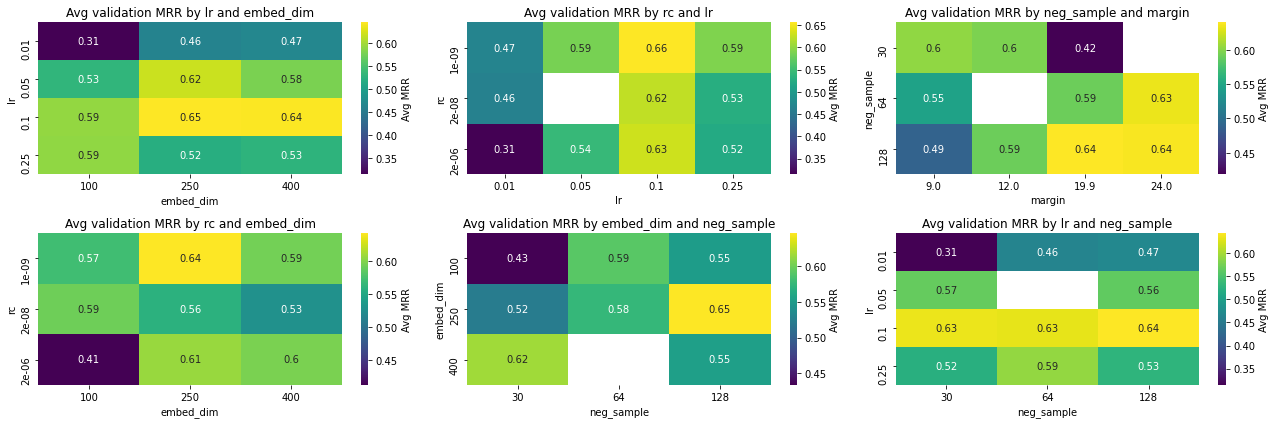

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(18, 6))

for ax, (x_param, y_param) in zip(axes.flatten(), pairs):
    heatmap_data = df.pivot_table(values='avg_mrr', index=y_param, columns=x_param)
    
    sns.heatmap(heatmap_data, annot=True, cmap='viridis', cbar_kws={'label': 'Avg MRR'}, ax=ax)
    ax.set_title(f'Avg validation MRR by {y_param} and {x_param}')
    ax.set_xlabel(x_param)
    ax.set_ylabel(y_param)

plt.tight_layout()
plt.show()